Chargement des contours des quartiers...
-> Colonne géographique IRIS identifiée : code_iris
Chargement du fichier INSEE 2018...
Recherche et chargement du fichier INSEE 2021...
-> Fichier 2021 détecté : BASE_TD_FILO_IRIS_2021_DISP.xlsx
-> Colonne IRIS 2021 identifiée : IRIS
-> Colonne niveau de vie 2021 identifiée : DISP_MED21
-> Fusion 2021 réussie ! 18 quartiers appariés.


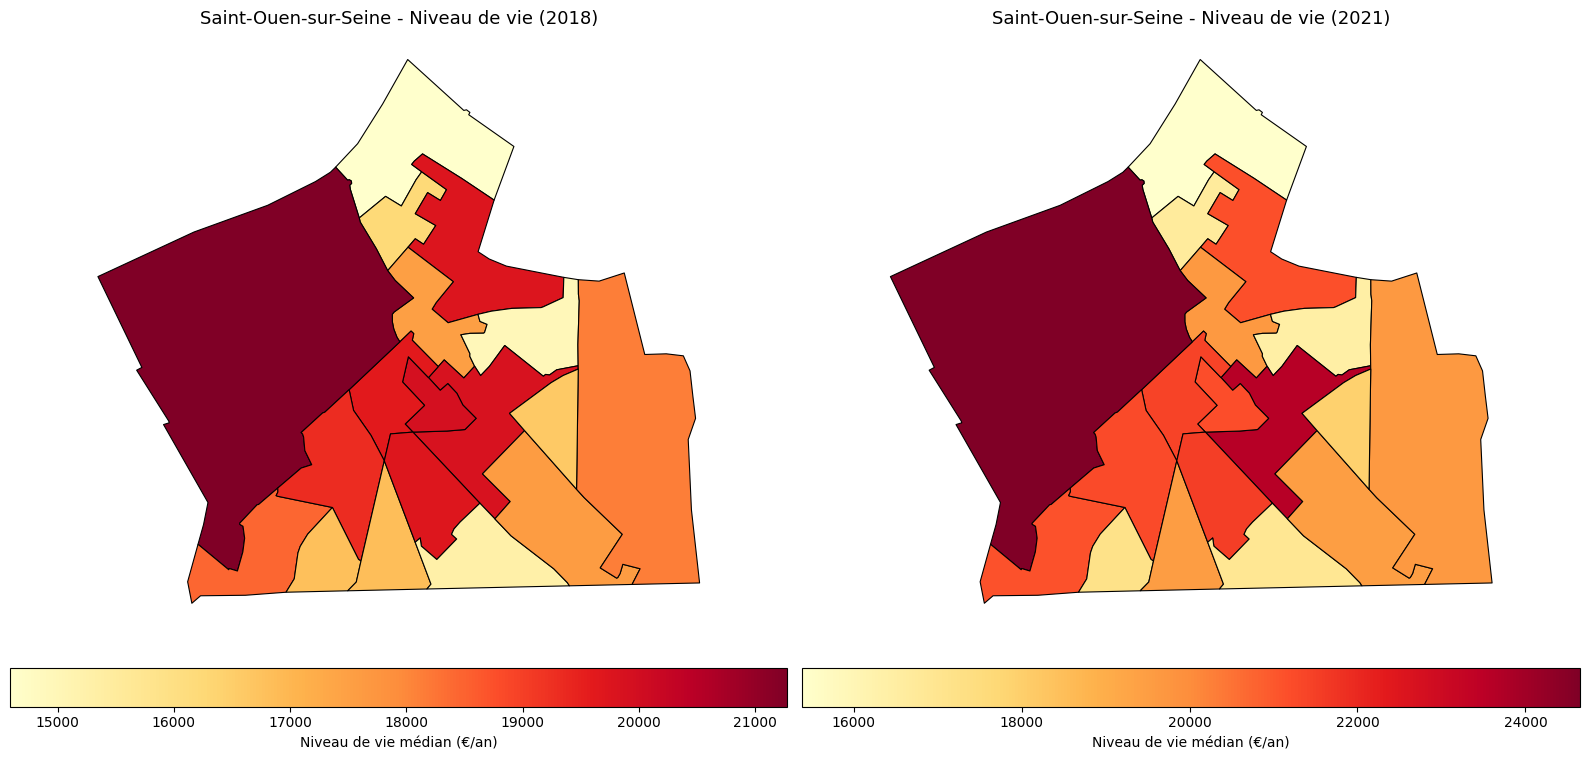

In [11]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Définition du dossier de travail
dossier_projet = Path("C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/projet_python_2a_ensae")

# ==============================================================================
# 1. Charger les contours des quartiers depuis votre fichier local 'iris.gpkg'
# ==============================================================================
print("Chargement des contours des quartiers...")
iris_all = gpd.read_file(dossier_projet / "iris.gpkg")

# Trouver la colonne qui contient les codes IRIS
col_geo_code = None
for col in iris_all.columns:
    sample = iris_all[col].astype(str).str.strip()
    if (sample.str.len() == 9).any() and sample.str.startswith('93').any():
        col_geo_code = col
        break

if col_geo_code is None:
    for c in ['CODE_IRIS', 'IRIS', 'code', 'DCODiIRIS']:
        if c in iris_all.columns:
            col_geo_code = c
            break

print(f"-> Colonne géographique IRIS identifiée : {col_geo_code}")

# Filtrer Saint-Ouen-sur-Seine (Code INSEE 93070)
st_ouen_iris = iris_all[iris_all[col_geo_code].astype(str).str.strip().str.startswith('93070')].copy()
st_ouen_iris[col_geo_code] = st_ouen_iris[col_geo_code].astype(str).str.strip().str.zfill(9)


# ==============================================================================
# 2. Charger et préparer les données de 2018
# ==============================================================================
print("Chargement du fichier INSEE 2018...")
file_2018 = dossier_projet / "BASE_TD_FILO_DISP_IRIS_2018.xlsx"
df_2018 = pd.read_excel(file_2018, skiprows=5)

col_iris_2018 = 'IRIS'
col_niv_2018 = 'DISP_MED18' if 'DISP_MED18' in df_2018.columns else [c for c in df_2018.columns if 'MED' in c][0]

df_2018[col_iris_2018] = df_2018[col_iris_2018].astype(str).str.strip().str.zfill(9)
df_2018[col_niv_2018] = pd.to_numeric(df_2018[col_niv_2018], errors='coerce')

# Fusion 2018
st_ouen_2018 = st_ouen_iris.merge(df_2018, left_on=col_geo_code, right_on=col_iris_2018, how='inner')


# ==============================================================================
# 3. Charger et préparer les données de 2021 (Sélection stricte du niveau de vie)
# ==============================================================================
print("Recherche et chargement du fichier INSEE 2021...")

fichiers_2021 = list(dossier_projet.glob("*2021*.xlsx")) + list(dossier_projet.glob("*2021*.XLSX"))
if not fichiers_2021:
    fichiers_2021 = list(dossier_projet.glob("*.xlsx"))

file_2021 = fichiers_2021[0]
print(f"-> Fichier 2021 détecté : {file_2021.name}")

df_2021 = pd.read_excel(file_2021, skiprows=5)

col_iris_2021 = 'IRIS' if 'IRIS' in df_2021.columns else df_2021.columns[0]

# Recherche ciblée : on cherche une colonne avec 'MED' ou 'DISP' et dont les valeurs moyennes sont réalistes (entre 10k et 40k)
col_niv_2021 = None
for c in df_2021.columns:
    if c == col_iris_2021:
        continue
    # Vérifie si le nom contient MED ou DISP
    if any(kw in str(c).upper() for kw in ['MED', 'DISP_MED']):
        s = pd.to_numeric(df_2021[c], errors='coerce')
        val_moy = s.dropna().mean()
        if 10000 <= val_moy <= 40000:
            col_niv_2021 = c
            break

# Si non trouvé par nom, on cherche par fourchette de valeurs réalistes pour un niveau de vie médian
if col_niv_2021 is None:
    for c in df_2021.columns:
        if c == col_iris_2021:
            continue
        s = pd.to_numeric(df_2021[c], errors='coerce')
        val_moy = s.dropna().mean()
        if 15000 <= val_moy <= 35000:
            col_niv_2021 = c
            break

if col_niv_2021 is None:
    raise ValueError("Impossible de trouver automatiquement la colonne de niveau de vie médian pour 2021.")

print(f"-> Colonne IRIS 2021 identifiée : {col_iris_2021}")
print(f"-> Colonne niveau de vie 2021 identifiée : {col_niv_2021}")

df_2021[col_iris_2021] = df_2021[col_iris_2021].astype(str).str.split('.').str[0].str.strip().str.zfill(9)
df_2021[col_niv_2021] = pd.to_numeric(df_2021[col_niv_2021], errors='coerce')

# Fusion 2021
st_ouen_2021 = st_ouen_iris.merge(df_2021, left_on=col_geo_code, right_on=col_iris_2021, how='inner')
print(f"-> Fusion 2021 réussie ! {len(st_ouen_2021)} quartiers appariés.")


# ==============================================================================
# 4. Générer les deux cartes côte à côte
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Carte 1 : 2018
st_ouen_2018.plot(
    ax=axes[0],
    column=col_niv_2018,
    cmap='YlOrRd',
    edgecolor='black',
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={'label': "Niveau de vie médian (€/an)", 'orientation': "horizontal", 'pad': 0.05}
)
axes[0].set_title("Saint-Ouen-sur-Seine - Niveau de vie (2018)", fontsize=13)
axes[0].axis('off')

# Carte 2 : 2021
st_ouen_2021.plot(
    ax=axes[1],
    column=col_niv_2021,
    cmap='YlOrRd',
    edgecolor='black',
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={'label': "Niveau de vie médian (€/an)", 'orientation': "horizontal", 'pad': 0.05}
)
axes[1].set_title("Saint-Ouen-sur-Seine - Niveau de vie (2021)", fontsize=13)
axes[1].axis('off')

plt.tight_layout()
plt.show()